# Retail Sales Analysis Project



# Importing libraries 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the Dataset



In [54]:
df = pd.read_csv("sales_raw.csv")


df_raw = df.copy()


df = df_raw.copy()

df.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Region,Sales_Channel,Product,Category,Quantity,Unit_Price,Unit_Cost,Discount,Payment_Method,Order_Status,Sales_Rep,Delivery_Days,Revenue,Profit
0,ORD-00001,14/04/2024,04/19/24,CUST-1016,North,Partner,Wireless Mouse,Accessories,1,23.31,8.50,0,Credit Card,Delivered,REP-02,5.0,23.31,14.81
1,ORD-00002,10/27/25,30-Oct-25,CUST-1082,West,Phone,Office Chair,Furniture,1,185.51,74.03,0.1,Credit Card,Shipped,REP-12,NaN,166.96,92.93
2,ORD-00003,2024-12-10,12/15/24,CUST-1136,East,Phone,Keyboard,Accessories,2,49.32,11.77,0.25,Cash on Delivery,Delivered,REP-13,5.0,73.98,50.44
3,ORD-00004,22/01/2025,2025-01-29,CUST-1099,Central,Phone,Laptop,Electronics,4,960.33,628.49,0.35,Cash on Delivery,Delivered,REP-12,7.0,2496.86,-17.10
4,ORD-00005,"Mar 22, 2024",03/25/24,CUST-1187,West,Phone,Wireless Mouse,Accessories,1,22.96,8.47,0.05,Bank Transfer,Processing,REP-03,NaN,21.81,13.34


# Understanding The Dataset



In [55]:

print("Dataset shape:", df.shape)


print("\nColumn names:")
print(df.columns.tolist())

df.info()

Dataset shape: (1000, 18)

Column names:
['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Region', 'Sales_Channel', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Unit_Cost', 'Discount', 'Payment_Method', 'Order_Status', 'Sales_Rep', 'Delivery_Days', 'Revenue', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        1000 non-null   object 
 1   Order_Date      1000 non-null   object 
 2   Ship_Date       928 non-null    object 
 3   Customer_ID     982 non-null    object 
 4   Region          986 non-null    object 
 5   Sales_Channel   1000 non-null   object 
 6   Product         992 non-null    object 
 7   Category        1000 non-null   object 
 8   Quantity        1000 non-null   int64  
 9   Unit_Price      991 non-null    float64
 10  Unit_Cost       1000 non-null   float64
 11  Discount        988 no

# Checking The Missing Values



In [8]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Ship_Date          72
Customer_ID        18
Region             14
Product             8
Unit_Price          9
Discount           12
Payment_Method     15
Sales_Rep          20
Delivery_Days     240
dtype: int64


# Checking The Duplicate Records



In [56]:

print("Duplicate rows:", df.duplicated().sum())


print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Order IDs: 12


# Removing The Duplicate Rows



In [13]:
before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Rows removed:", before - after)
print("Rows remaining:", len(df))

Rows removed: 0
Rows remaining: 1000


# Fixing The Date Columns



In [15]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce", dayfirst=False
)

df["Ship_Date"] = pd.to_datetime(
    df["Ship_Date"], errors="coerce", dayfirst=False
)

print(df[["Order_Date", "Ship_Date"]].dtypes)

df[["Order_Date", "Ship_Date"]].head()

Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object


,Order_Date,Ship_Date
0,2024-04-14,2024-04-19
1,NaT,2025-10-30
2,NaT,2024-12-15
3,2025-01-22,2025-01-29
4,NaT,2024-03-25


# Fixing The Numeric Columns



In [57]:

number_columns = [
    "Quantity",
    "Unit_Price",
    "Unit_Cost",
    "Discount",
    "Delivery_Days",
    "Revenue",
    "Profit"
]


df["Discount"] = (
    df["Discount"]
    .astype("string")
    .str.replace("%", "", regex=False)
)

for col in number_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[number_columns].dtypes

Quantity           int64
Unit_Price       float64
Unit_Cost        float64
Discount         Float64
Delivery_Days    float64
Revenue          float64
Profit           float64
dtype: object

# Handling The Missing Values

In [58]:

df = df.dropna(subset=["Order_ID"])


text_columns = [
    "Customer_ID",
    "Region",
    "Sales_Channel",
    "Product",
    "Category",
    "Payment_Method",
    "Order_Status",
    "Sales_Rep"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")


print(df.isnull().sum())

Order_ID            0
Order_Date          0
Ship_Date          72
Customer_ID         0
Region              0
Sales_Channel       0
Product             0
Category            0
Quantity            0
Unit_Price          9
Unit_Cost           0
Discount           12
Payment_Method      0
Order_Status        0
Sales_Rep           0
Delivery_Days     240
Revenue             0
Profit              0
dtype: int64


# Checking Invalid Values



In [50]:
print("Invalid quantity:", (df["Quantity"] <= 0).sum())
print("Negative unit price:", (df["Unit_Price"] < 0).sum())
print("Negative unit cost:", (df["Unit_Cost"] < 0).sum())

print(
    "Invalid discount:",
    ((df["Discount"] < 0) | (df["Discount"] > 1)).sum()
)

print(
    "Shipping before order:",
    (df["Ship_Date"] < df["Order_Date"]).sum()
)

Invalid quantity: 0
Negative unit price: 0
Negative unit cost: 0
Invalid discount: 0
Shipping before order: 0


In [59]:
df.loc[df["Quantity"] <= 0, "Quantity"] = np.nan
df.loc[df["Unit_Price"] < 0, "Unit_Price"] = np.nan
df.loc[df["Unit_Cost"] < 0, "Unit_Cost"] = np.nan

df.loc[
    (df["Discount"] < 0) | (df["Discount"] > 1),
    "Discount"
] = np.nan


bad_dates = df["Ship_Date"] < df["Order_Date"]
df.loc[bad_dates, "Ship_Date"] = pd.NaT

print("Invalid values checked.")

Invalid values checked.


# Checking  Revenue and Profit

In [60]:

df["Calculated_Revenue"] = (
    df["Quantity"]
    * df["Unit_Price"]
    * (1 - df["Discount"])
)


df["Calculated_Cost"] = df["Quantity"] * df["Unit_Cost"]


df["Calculated_Profit"] = (
    df["Calculated_Revenue"] - df["Calculated_Cost"]
)

df[
    [
        "Revenue",
        "Calculated_Revenue",
        "Profit",
        "Calculated_Profit"
    ]
].head()

,Revenue,Calculated_Revenue,Profit,Calculated_Profit
0,23.31,23.31,14.81,14.81
1,166.96,166.959,92.93,92.929
2,73.98,73.98,50.44,50.44
3,2496.86,2496.858,-17.10,-17.102
4,21.81,21.812,13.34,13.342


# Final Data Quality Check



In [51]:
print("Final dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
df.info()

Final dataset shape: (1000, 21)

Duplicate rows: 3

Missing values:
Order_ID                0
Order_Date            779
Ship_Date              86
Customer_ID             0
Region                  0
Sales_Channel           0
Product                 0
Category                0
Quantity                4
Unit_Price              9
Unit_Cost               2
Discount               25
Payment_Method          0
Order_Status            0
Sales_Rep               0
Delivery_Days         240
Revenue                 0
Profit                  0
Calculated_Revenue     38
Calculated_Cost         6
Calculated_Profit      40
dtype: int64

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Order_ID            1000 non-null   object        
 1   Order_Date          221 non-null    datetime64[ns]
 2   Ship_Date           914 n

# Saving the Cleaned Dataset



In [24]:
df.to_csv("sales_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


# Data Cleaning Done 

# Exploratory Data Analysis (EDA)

#  Overview of the Cleaned Data



In [25]:
print("Rows and columns:", df.shape)

df.describe()

Rows and columns: (1000, 21)


,Order_Date,Ship_Date,Quantity,Unit_Price,Unit_Cost,Discount,Delivery_Days,Revenue,Profit,Calculated_Revenue,Calculated_Cost,Calculated_Profit
count,221,914,996.000000,991.000000,998.000000,975.0,760.000000,1000.000000,1000.000000,962.0,994.000000,960.0
mean,2025-01-27 01:18:11.402714880,2025-01-04 02:40:42.013129216,7.328313,614.033673,254.157164,0.097179,4.255263,667.660150,296.514120,2555.048246,988.677022,1549.119739
min,2024-01-05 00:00:00,2024-01-04 00:00:00,1.000000,0.000000,2.760000,0.0,-4.000000,8.920000,-381.890000,0.0,2.800000,-199360.096
25%,2024-08-12 00:00:00,2024-07-05 00:00:00,2.000000,54.305000,11.935000,0.0,2.000000,98.200000,68.812500,97.495,25.480000,67.9385
50%,2025-02-07 00:00:00,2025-01-05 12:00:00,3.000000,108.960000,26.535000,0.1,4.000000,260.970000,161.515000,258.7085,89.600000,160.057
75%,2025-08-05 00:00:00,2025-07-05 00:00:00,4.000000,236.210000,90.225000,0.15,5.000000,704.972500,375.595000,713.124,304.230000,374.895
max,2025-12-31 00:00:00,2026-01-07 00:00:00,999.000000,99999.000000,50000.000000,0.35,365.000000,11072.140000,3896.100000,379996.2,200000.000000,379554.12
std,NaN,NaN,63.051894,6335.650881,2738.957500,0.087456,14.027663,1183.763599,404.960236,22901.99931,8821.222619,22943.02074


#  Overall Sales and Profit



In [26]:
total_revenue = df["Calculated_Revenue"].sum()
total_cost = df["Calculated_Cost"].sum()
total_profit = df["Calculated_Profit"].sum()
average_quantity = df["Quantity"].mean()

print("Total Revenue:", round(total_revenue, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Profit:", round(total_profit, 2))
print("Average Quantity:", round(average_quantity, 2))

Total Revenue: 2457956.41
Total Cost: 982744.96
Total Profit: 1487154.95
Average Quantity: 7.33


In [27]:
print(
    "Rows with calculated revenue:",
    df["Calculated_Revenue"].notna().sum()
)

print(
    "Rows with calculated profit:",
    df["Calculated_Profit"].notna().sum()
)

Rows with calculated revenue: 962
Rows with calculated profit: 960


#  Sales and Profit by Category



In [28]:
category_sales = df.groupby("Category")[
    "Calculated_Revenue"
].sum().sort_values(ascending=False)

print(category_sales)

Category
Electronics        1350876.542
Furniture          578127.3555
Accessories        525301.9975
Office Supplies       3650.518
Name: Calculated_Revenue, dtype: Float64


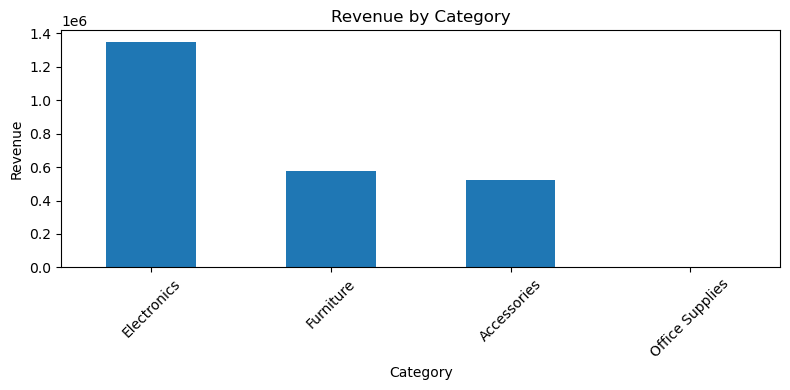

In [29]:
category_sales.plot(kind="bar", figsize=(8, 4))

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
category_profit = df.groupby("Category")[
    "Calculated_Profit"
].sum().sort_values(ascending=False)

print(category_profit)

Category
Electronics         864323.875
Accessories        476721.3175
Furniture           143281.369
Office Supplies       2828.388
Name: Calculated_Profit, dtype: Float64


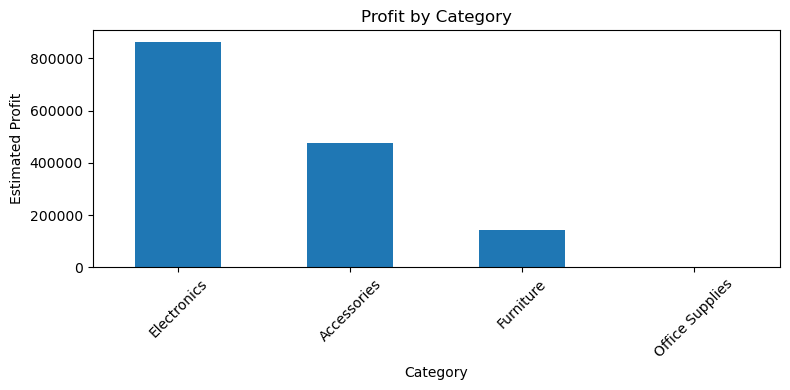

In [31]:
category_profit.plot(kind="bar", figsize=(8, 4))

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Estimated Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Sales and Profit by Region



In [33]:
region_summary = df.groupby("Region")[
    ["Calculated_Revenue", "Calculated_Profit"]
].sum().sort_values(
    by="Calculated_Profit",
    ascending=False
)

region_summary

,Calculated_Revenue,Calculated_Profit
Region,,
East,758165.262,678778.832
West,656013.298,308921.358
Wset,285430.86,285002.47
South,331977.0995,179346.973
Central,221200.9685,129405.3185
Centre,9861.463,3115.303
Unknown,4303.0445,2264.3145
Est,2255.746,1538.466
Soth,6922.6075,982.3475


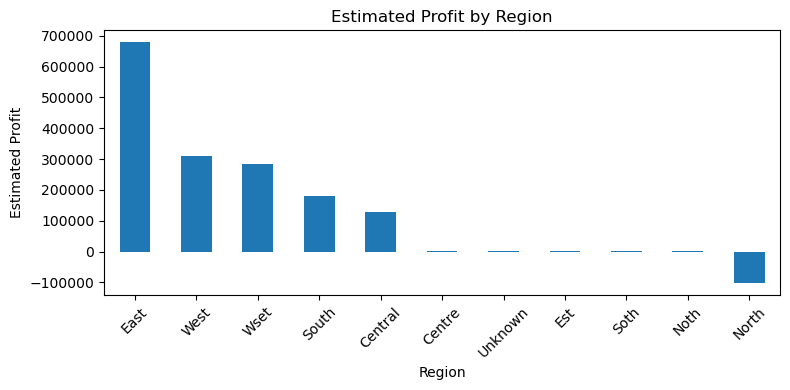

In [34]:
region_summary["Calculated_Profit"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Estimated Profit by Region")
plt.xlabel("Region")
plt.ylabel("Estimated Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Performance by Sales Channel



In [35]:
channel_summary = df.groupby("Sales_Channel")[
    ["Calculated_Revenue", "Calculated_Profit"]
].sum().sort_values(
    by="Calculated_Revenue",
    ascending=False
)

channel_summary

,Calculated_Revenue,Calculated_Profit
Sales_Channel,,
Phone,1109685.434,827007.9375
Partner,701505.9185,509055.6185
Online,386532.9215,104004.3345
Retail,247205.0445,42096.4245
Phone Order,11874.8725,4187.0425
On-Line,1152.222,803.592


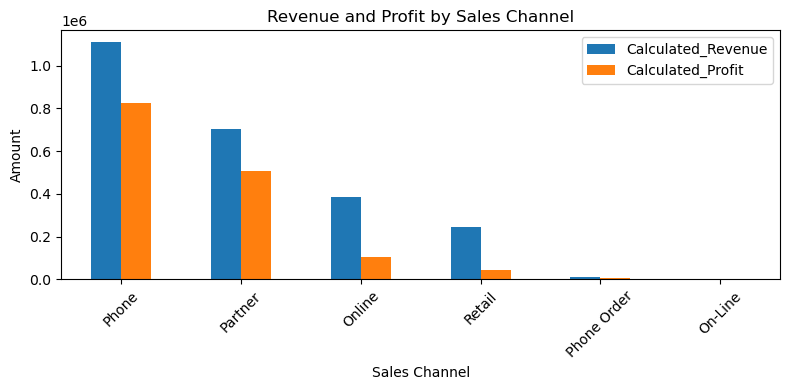

In [36]:
channel_summary.plot(kind="bar", figsize=(8, 4))

plt.title("Revenue and Profit by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Order Status Analysis



In [37]:
df["Order_Status"].value_counts()

Order_Status
Delivered     677
Shipped       113
Returned       72
Processing     70
Cancelled      58
Deliverd        9
Return          1
Name: count, dtype: int64

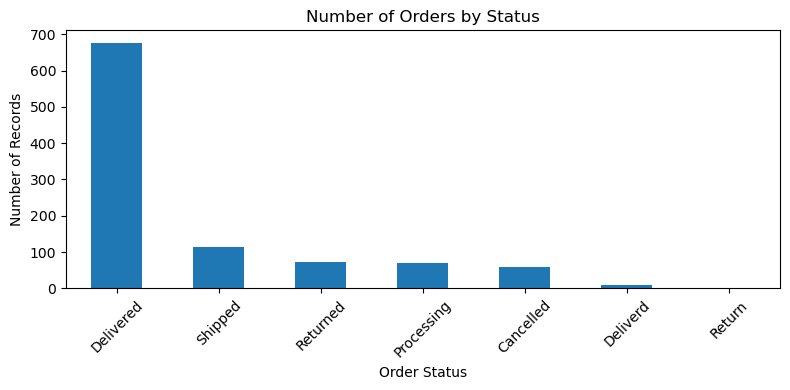

In [38]:
df["Order_Status"].value_counts().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Number of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Delivery Time Analysis



In [40]:
print("Average delivery days:", round(df["Delivery_Days"].mean(), 2))

delivery_by_region = df.groupby("Region")[
    "Delivery_Days"
].mean().sort_values(ascending=False)

delivery_by_region

Average delivery days: 4.26


Region
West       6.511905
North      4.163121
Centre     4.000000
Noth       4.000000
Soth       3.800000
East       3.584507
South      3.468750
Est        3.333333
Central    3.290323
Unknown    3.272727
Wset       2.500000
Name: Delivery_Days, dtype: float64

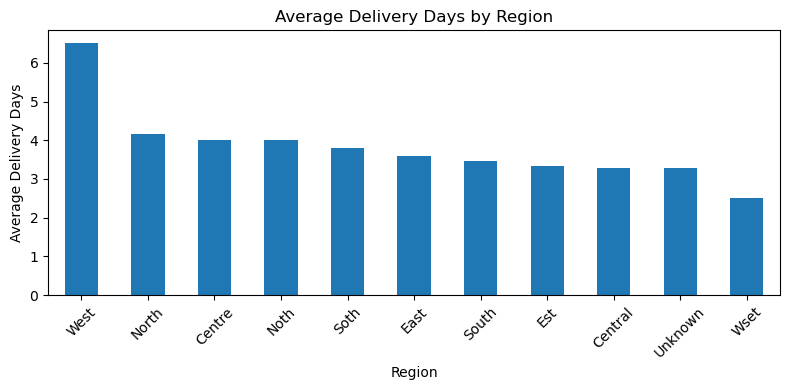

In [41]:
delivery_by_region.plot(kind="bar", figsize=(8, 4))

plt.title("Average Delivery Days by Region")
plt.xlabel("Region")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#  Top Products by Revenue



In [43]:
top_products = df.groupby("Product")[
    "Calculated_Revenue"
].sum().sort_values(ascending=False)

top_products.head(10)

Product
Monitor           962018.4935
Desk               374793.586
Keyboard          334885.5355
Laptop            293363.9695
Office Chair        199854.41
Headphones        181649.5055
Printer            61350.4255
Webcam             27792.4995
Wireless Mouse       6294.005
Unknown              4410.111
Name: Calculated_Revenue, dtype: Float64

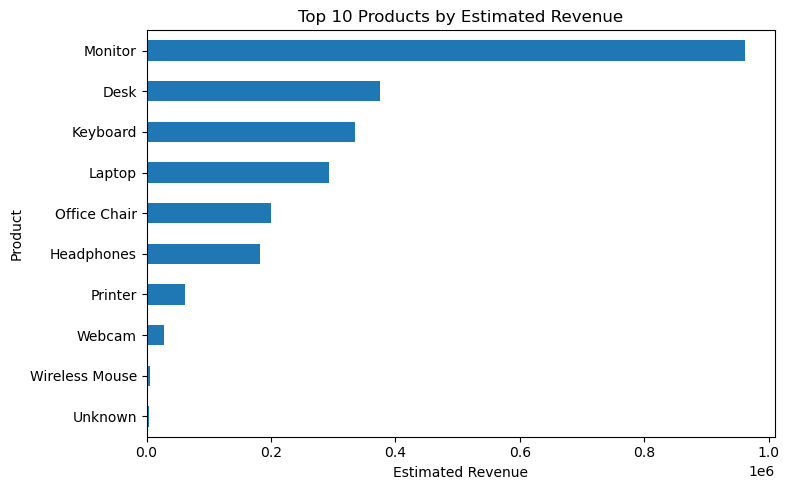

In [44]:
top_products.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Products by Estimated Revenue")
plt.xlabel("Estimated Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

#  Correlation Analysis



In [45]:
numeric_columns = [
    "Quantity",
    "Unit_Price",
    "Discount",
    "Calculated_Revenue",
    "Calculated_Profit"
]

correlation = df[numeric_columns].corr()

correlation

,Quantity,Unit_Price,Discount,Calculated_Revenue,Calculated_Profit
Quantity,1.000000,-0.004382,0.022184,0.375543,0.224309
Unit_Price,-0.004382,1.000000,-0.014533,0.900345,0.900148
Discount,0.022184,-0.014533,1.000000,-0.012706,-0.017535
Calculated_Revenue,0.375543,0.900345,-0.012706,1.000000,0.923442
Calculated_Profit,0.224309,0.900148,-0.017535,0.923442,1.000000


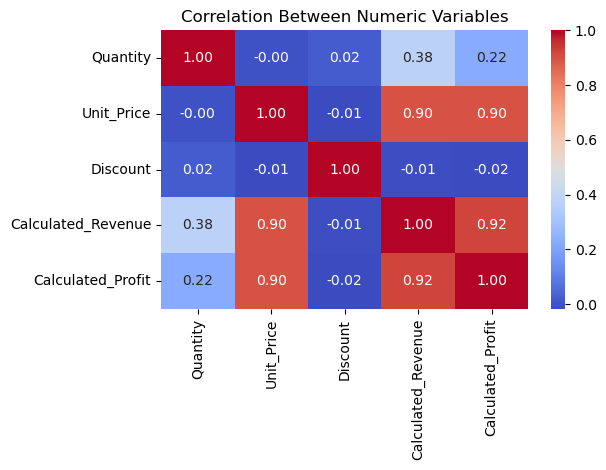

In [46]:
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()

# Important business insights 



In [61]:

best_category = df.groupby("Category")[
    "Calculated_Profit"
].sum().idxmax()


best_region = df.groupby("Region")[
    "Calculated_Profit"
].sum().idxmax()


best_channel = df.groupby("Sales_Channel")[
    "Calculated_Profit"
].sum().idxmax()

print("Best Category:", best_category)
print("Best Region:", best_region)
print("Best Sales Channel:", best_channel)

Best Category: Electronics
Best Region: East
Best Sales Channel: Phone


# EDA Process Completed